<a href="https://colab.research.google.com/github/Srivashinie/neural-network-from-scratch-mnist/blob/main/neural_network_from_scratch_mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Handwritten Digit Recognition from Scratch (NumPy)

A neural network that classifies MNIST digits (0–9), with all the math written in NumPy.
PyTorch is used only to download the dataset.

**Network:** 784 pixel inputs -> hidden layer (activation) -> 10 outputs -> softmax probabilities

**Final result:** 98.24% accuracy on the test set.

**Steps:** setup -> data  preprocessing & split -> building blocks -> initialization ->
forward pass -> backpropagation & gradient check -> training -> evaluation -> experiments -> final test

In [68]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


##Step 1: Setup
Import NumPy (all the math) and Matplotlib (plots), and create one random generator with a fixed seed.

Why a fixed seed: every run gives identical results, so any change in accuracy comes from a change in the code or the settings.

Note: if results look strange, use Runtime -> Restart and run all. Cells can run in any order, so a variable may still hold an old value.

In [69]:
import numpy as np
import matplotlib.pyplot as plt
seed=np.random.default_rng(42) #the sequence of random numbers it produces is reproducible

In [70]:
print(seed.integers(1,10, size=10))

[1 7 6 4 4 8 1 7 2 1]


##Step 2: Dataset
MNIST has 60,000 training and 10,000 test images. Each is a 28×28 grayscale picture with a label 0–9.
torchvision downloads the data, and .numpy() converts it to NumPy arrays.

What to notice in the output:
- Images are uint8: whole numbers 0–255. This type can't hold decimals and silently wraps around
  on overflow (200 + 100 = 44), so it must be converted to float before any math.
- Labels are integers 0–9.

In [71]:
from torchvision import datasets

train_set = datasets.MNIST(root="./data", train=True, download=True)
test_set  = datasets.MNIST(root="./data", train=___, download=True)

In [72]:
print(train_set)
print(test_set)

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
Dataset MNIST
    Number of datapoints: 10000
    Root location: ./data
    Split: Test


In [73]:
x_train=train_set.data.numpy()
y_train=train_set.targets.numpy()
x_test=test_set.data.numpy()
y_test=test_set.targets.numpy()

In [74]:
for name, arr in [("x_train", x_train), ("y_train", y_train),
                  ("x_test", x_test), ("y_test", y_test)]:
    print(f"{name}: shape={arr.shape}, dtype={arr.dtype}, min={arr.min()}, max={arr.max()}")

x_train: shape=(60000, 28, 28), dtype=uint8, min=0, max=255
y_train: shape=(60000,), dtype=int64, min=0, max=9
x_test: shape=(10000, 28, 28), dtype=uint8, min=0, max=255
y_test: shape=(10000,), dtype=int64, min=0, max=9


Look at the data
- Image grid: check that the pictures match their labels.
- Bar chart: each digit has about 5,400–6,700 images, so the classes are roughly balanced.

Why balance matters: if 90% of the images were 1s, a model that always answers "1" would score 90%
while learning nothing. With balanced classes, plain accuracy is a fair measure.

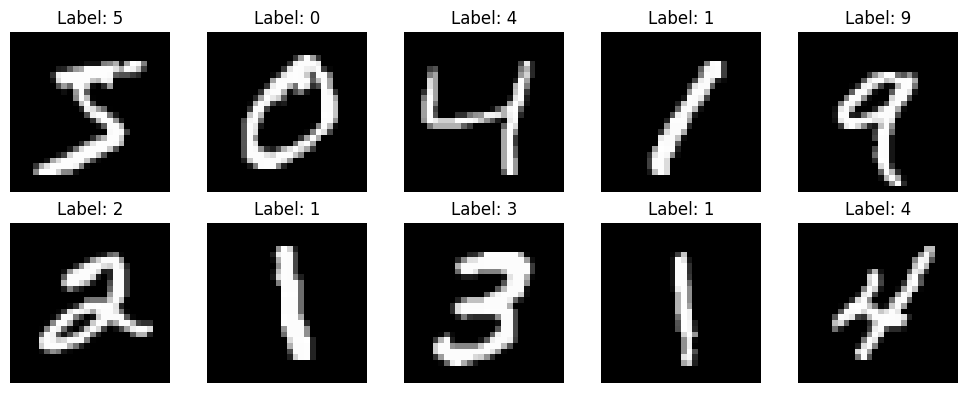

In [75]:
fig,axes=plt.subplots(2,5,figsize=(10,4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

[5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


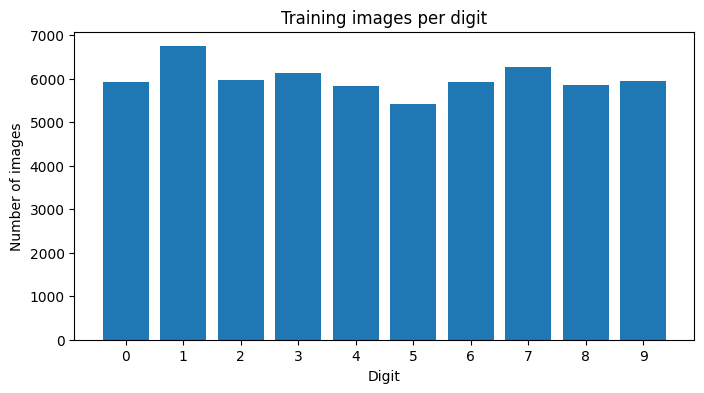

In [76]:
counts = np.bincount(y_train)
print(counts)

plt.figure(figsize=(8, 4))
plt.bar(range(10), counts)
plt.xticks(range(10))
plt.xlabel("Digit")
plt.ylabel("Number of images")
plt.title("Training images per digit")
plt.show()

##Step 3: Preprocessing and Split
1. Convert to float32 and divide by 255 -> pixel values between 0 and 1. Large inputs (up to 255)
   make X @ W explode and training unstable.
2. Flatten each 28×28 image into a row of 784 numbers, because a fully connected network takes one vector per image.
3. Shuffle, then split the 60,000 training images into train (50,000) and validation (10,000).

| Split | Size | Purpose |
|---|---|---|
| Train | 50,000 | learn the weights |
| Validation | 10,000 | compare experiments, choose settings |
| Test | 10,000 | one final, honest score at the very end |

Why shuffle indices, not the arrays: shuffling X and y separately would mix up which label goes with
which image. One shuffled list of row numbers keeps them paired.


In [77]:
x_train = x_train.astype(np.float32) / 255.0
x_test  = x_test.astype(np.float32) / 255.0

In [78]:
x_train = x_train.reshape(x_train.shape[0], 784)
x_test  = x_test.reshape(x_test.shape[0],784)

In [79]:
n = x_train.shape[0]
indices = seed.permutation(n)        # a random order of the numbers 0 .. n-1

val_size = 10000
val_idx   = indices[:val_size]             # first 10,000 shuffled indices
train_idx = indices[val_size:]
print(np.shape(val_idx))          # the rest

x_val, y_val = x_train[val_idx], y_train[val_idx]
x_tr,  y_tr  = x_train[train_idx], y_train[train_idx]

(10000,)


Check the split
- Shapes: (50000, 784), (10000, 784), (10000, 784), all float32 with values 0.0 to 1.0.
- Reshaping a row back to 28×28 should show a clean digit that matches its label.

In [80]:
print(x_val.shape, x_val.shape)
print(x_tr.shape, y_tr.shape)
print(x_test.shape, y_test.shape)

(10000, 784) (10000, 784)
(50000, 784) (50000,)
(10000, 784) (10000,)


In [81]:
for name, arr in [("x_tr", x_tr), ("x_val", x_val), ("x_test", x_test)]:
    print(name, arr.shape, arr.dtype, arr.min(), arr.max())

x_tr (50000, 784) float32 0.0 1.0
x_val (10000, 784) float32 0.0 1.0
x_test (10000, 784) float32 0.0 1.0


##Step 4: Building Blocks

### Activation functions
Without an activation, stacking layers is pointless: two linear steps are still one linear step.
The activation adds the non-linearity that lets the network learn curved decision boundaries.

Each activation needs the function (for the forward pass) and its derivative (slope, for backprop):

| Activation | f(z) | f′(z) | Max slope |
|---|---|---|---|
| Sigmoid | $1/(1+e^{-z})$ | $f(z)(1-f(z))$ | 0.25 |
| Tanh | $\tanh(z)$ | $1-\tanh^2(z)$ | 1 |
| ReLU | $\max(0,z)$ | 1 if z > 0 else 0 | 1 |
| Leaky ReLU | z if z > 0 else 0.01z | 1 if z > 0 else 0.01 | 1 |

They're stored in the ACTIVATIONS dictionary, so switching activation anywhere is a small change.

In [82]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def sigmoid_deriv(z):
    s = sigmoid(z)
    return s*(1-s)

def tanh(z):
    return np.tanh(z)

def tanh_deriv(z):
    return (1-tanh(z)**2)

def relu(z):
    return np.maximum(0, z)

def relu_deriv(z):
    return (z > 0).astype(np.float32)

def leaky_relu(z, alpha=0.01):
    return np.where(z > 0, z, alpha*z)

def leaky_relu_deriv(z, alpha=0.01):
    return np.where(z > 0, 1, alpha)

In [83]:
ACTIVATIONS = {
    "sigmoid":    (sigmoid, sigmoid_deriv),
    "tanh":       (tanh, tanh_deriv),
    "relu":       (relu, relu_deriv),
    "leaky_relu": (leaky_relu, leaky_relu_deriv),
}

# Usage:
f, f_deriv = ACTIVATIONS["relu"]

Plot and check the derivatives
- The plots show each function above its slope. Sigmoid's slope never goes above 0.25, and sigmoid and tanh
  go flat for large |z|. During backprop, gradients get multiplied by these slopes, so small slopes mean slow learning
  (the *vanishing gradient* problem).
- The numerical check estimates each slope as $\frac{f(z+h)-f(z-h)}{2h}$ and compares it with the formula.
  Differences around 1e-10 mean the derivative is correct.

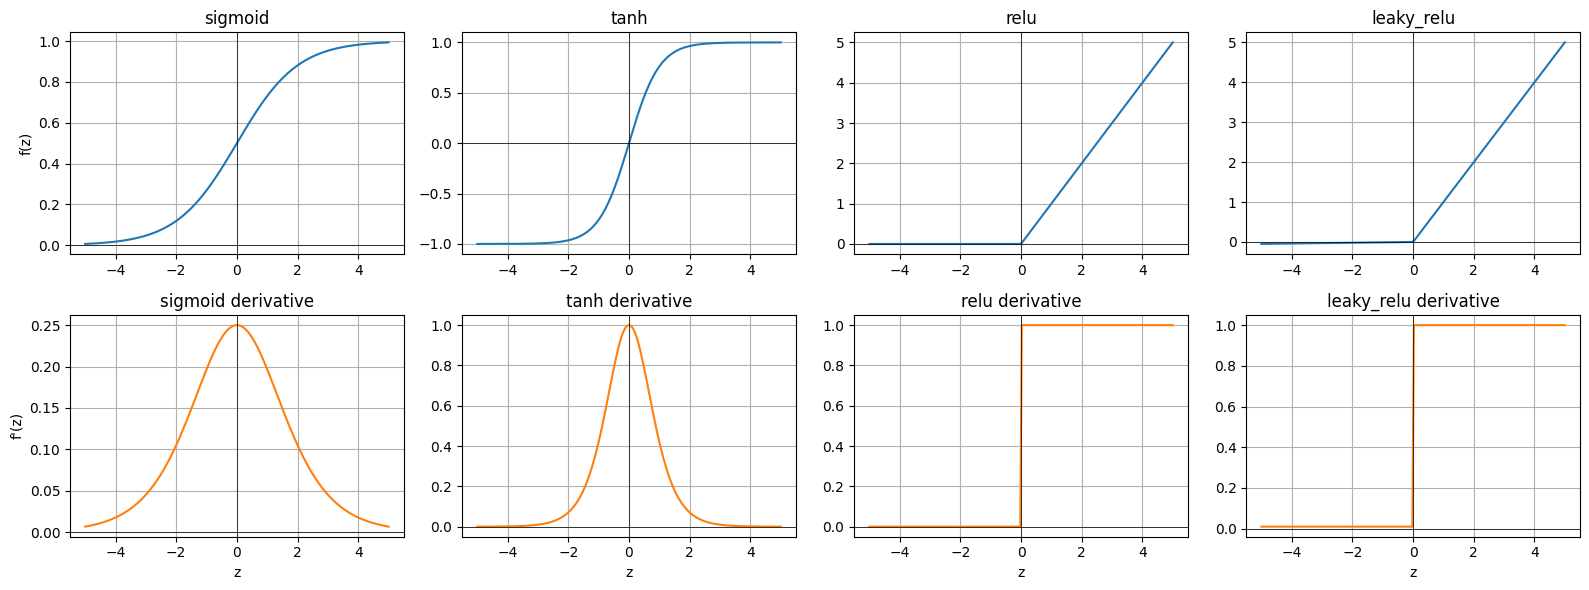

In [84]:
z = np.linspace(-5, 5, 200)   # 200 evenly spaced points from -5 to 5

fig, axes = plt.subplots(2, 4, figsize=(16, 6))

for col, (name, (f, df)) in enumerate(ACTIVATIONS.items()):
    # Top row: the activation function
    axes[0, col].plot(z, f(z), color="tab:blue")
    axes[0, col].set_title(name)
    axes[0, col].grid(True)
    axes[0, col].axhline(0, color="black", linewidth=0.5)
    axes[0, col].axvline(0, color="black", linewidth=0.5)

    # Bottom row: its derivative
    axes[1, col].plot(z, df(z), color="tab:orange")
    axes[1, col].set_title(f"{name} derivative")
    axes[1, col].grid(True)
    axes[1, col].axhline(0, color="black", linewidth=0.5)
    axes[1, col].axvline(0, color="black", linewidth=0.5)

axes[0, 0].set_ylabel("f(z)")
axes[1, 0].set_ylabel("f'(z)")
for ax in axes[1]:
    ax.set_xlabel("z")

plt.tight_layout()
plt.show()

In [85]:
h = 1e-5
z_test = np.array([-2.0, -0.5, 0.3, 1.7])

for name, (f, df) in ACTIVATIONS.items():
    numeric  = (f(z_test + h) - f(z_test - h)) / (2*h)
    analytic = df(z_test)
    print(f"{name:11s} max difference: {np.max(np.abs(numeric - analytic)):.2e}")

sigmoid     max difference: 4.32e-12
tanh        max difference: 2.23e-11
relu        max difference: 6.55e-12
leaky_relu  max difference: 6.55e-12


##Softmax

Turns the 10 raw output scores into probabilities between 0 and 1 that add up to 1:

$$\text{softmax}(z_i) = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

For Stability- subtract the row's maximum first. np.exp(1000) overflows to inf, giving nan.
Subtracting the same number from every score doesn't change the result. axis=1 normalizes each row (each image) separately.

In [86]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)    # stability: stops exp() overflowing
    exp_z = np.exp(z)
    return exp_z / exp_z.sum(axis=1, keepdims=True)

In [87]:
test = np.array([[1.0, 2.0, 3.0],
                 [1000.0, 1001.0, 1002.0]])   # huge values: a naive softmax gives nan
p = softmax(test)
print(p)
print("row sums:", p.sum(axis=1))

[[0.09003057 0.24472847 0.66524096]
 [0.09003057 0.24472847 0.66524096]]
row sums: [1. 1.]


##One-hot encoding

Label 3 → [0,0,0,1,0,0,0,0,0,0]. This matches the shape of the network's 10 outputs and describes
the perfect answer ("100% on digit 3"). It also treats digits as categories and not quantities.

In [88]:
def one_hot(y, num_classes=10):
    out = np.zeros((len(y),num_classes))
    out[np.arange(len(y)), y] = 1
    return out

In [89]:
print(one_hot(np.array([3, 0, 9])))

[[0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]]


##Cross-entropy loss

For each image: $-\log(\text{probability given to the correct digit})$, averaged over the batch.

| Prediction | Loss |
|---|---|
| 100% on the right digit | 0 |
| unsure (equal probabilities) | ln(number of classes) |
| 98% sure of a wrong digit | ≈ 4.6 |

Being confidently wrong is punished hardest. For an untrained network with 10 classes, expect **≈ ln(10) = 2.30**.

In [90]:
def cross_entropy(probs, y_onehot):
    eps = 1e-12
    return -np.mean(np.sum(y_onehot * np.log(probs + eps), axis=1))

In [91]:
y = one_hot(np.array([2, 0]), num_classes=3)
perfect = np.array([[0.0, 0.0, 1.0], [1.0, 0.0, 0.0]])
uniform = np.full((2, 3), 1/3)
wrong   = np.array([[0.98, 0.01, 0.01], [0.01, 0.98, 0.01]])

for name, p in [("perfect", perfect), ("uniform", uniform), ("wrong", wrong)]:
    print(name, cross_entropy(p, y))

perfect -1.000088900581841e-12
uniform 1.0986122886651097
wrong 4.605170185888091


##Step 5: Initialize the parameters

| Parameter | Shape | Meaning |
|---|---|---|
| W1 | (784, hidden) | weights from every pixel to every hidden neuron |
| b1 | (1, hidden) | one bias per hidden neuron |
| W2 | (hidden, 10) | weights from hidden neurons to outputs |
| b2 | (1, 10) | one bias per output |

With 128 hidden neurons that's 101,770 learnable parameters.

Methods to initialize: zeros, small (×0.01), Xavier (×√(1/inputs), for sigmoid/tanh), He (×√(2/inputs), for ReLU).

- Why not zeros: every neuron would compute the same thing, get the same update and stay identical forever.
- Why scaling: it keeps each layer's output at a sensible size. Too large explodes, too small fades away.

In [92]:
def init_params(input_size, hidden_size, output_size, method="he", rng=None):
    if rng is None:
        rng = np.random.default_rng(42)

    def make_weights(fan_in, fan_out):
        if method == "zeros":
            return np.zeros((fan_in, fan_out))
        elif method == "small":
            return rng.standard_normal((fan_in, fan_out)) * 0.01
        elif method == "xavier":
            return rng.standard_normal((fan_in, fan_out)) * np.sqrt(1 / fan_in)
        elif method == "he":
            return rng.standard_normal((fan_in, fan_out)) * np.sqrt(2 / fan_in)
        else:
            raise ValueError(f"Unknown init method: {method}")

    params = {
        "W1": make_weights(input_size, hidden_size),
        "b1": np.zeros((1, hidden_size)),
        "W2": make_weights(hidden_size, output_size),
        "b2": np.zeros((1, output_size)),
    }
    return params

In [93]:
params = init_params(784, 128, 10, method="he")

total = 0
for name, value in params.items():
    print(f"{name}: shape={value.shape}, mean={value.mean():.4f}, std={value.std():.4f}")
    total += value.size
print("Total learnable parameters:", total)

W1: shape=(784, 128), mean=-0.0002, std=0.0507
b1: shape=(1, 128), mean=0.0000, std=0.0000
W2: shape=(128, 10), mean=0.0001, std=0.1270
b2: shape=(1, 10), mean=0.0000, std=0.0000
Total learnable parameters: 101770


Compare the methods
- Histograms: three bell curves centred on 0 with growing widths (small < Xavier < He).
- Passing real images through layer 1 shows how much signal each method lets through. Zeros gives none.
- The np.allclose check confirms that with zeros, hidden neurons are identical.

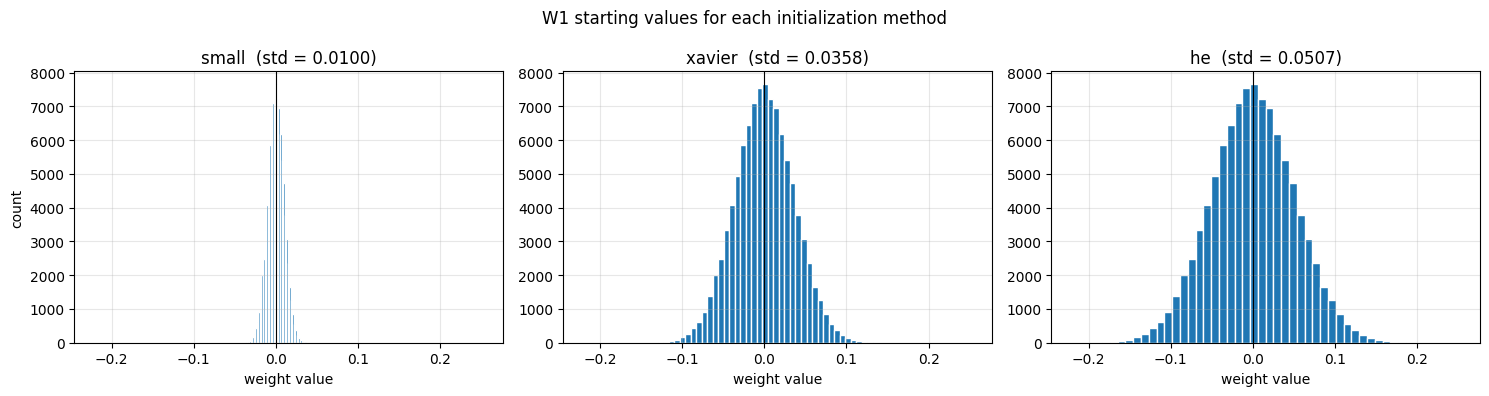

In [94]:
methods = ["small", "xavier", "he"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)

for ax, method in zip(axes, methods):
    p = init_params(784, 128, 10, method=method)
    w = p["W1"].flatten()                      # 784 × 128 = 100,352 values in one list

    ax.hist(w, bins=50, color="tab:blue", edgecolor="white")
    ax.set_title(f"{method}  (std = {w.std():.4f})")
    ax.set_xlabel("weight value")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("count")
plt.suptitle("W1 starting values for each initialization method")
plt.tight_layout()
plt.show()

In [95]:
X_sample = x_tr[:1000]

for method in ["zeros", "small", "xavier", "he"]:
    p = init_params(784, 128, 10, method=method)
    Z1 = X_sample @ p["W1"] + p["b1"]
    print(f"{method:7s}  Z1 std = {Z1.std():.4f}")

zeros    Z1 std = 0.0000
small    Z1 std = 0.0930
xavier   Z1 std = 0.3322
he       Z1 std = 0.4698


In [96]:
p = init_params(784, 128, 10, method="zeros")
Z1 = X_sample @ p["W1"] + p["b1"]
print(np.allclose(Z1[:, 0], Z1[:, 1]))   # are neuron 0 and neuron 1 identical?

True


##Step 6: Forward Pass

| Step | Calculation | Shape |
|---|---|---|
| input | X | (B, 784) |
| linear | Z1 = X @ W1 + b1 | (B, hidden) |
| activation | A1 = act(Z1) | (B, hidden) |
| linear | Z2 = A1 @ W2 + b2 | (B, 10) |
| probabilities | A2 = softmax(Z2) | (B, 10) |

B = batch size. A single @ handles the whole batch at once (vectorization), far faster than loops.
The cache keeps Z1, A1 and the rest because backprop needs them.
A single image must still be a batch of one: x[0:1] → (1, 784), not x[0] → (784,).

In [97]:
def forward(X, params, activation="relu"):
    act, _ = ACTIVATIONS[activation]       # take the function; the derivative is for Step 6

    Z1 = X @ params["W1"] + params["b1"]
    A1 = act(Z1)
    Z2 = A1 @ params["W2"] + params["b2"]
    A2 = softmax(Z2)

    cache = {"X": X, "Z1": Z1, "A1": A1, "Z2": Z2, "A2": A2}
    return A2, cache

In [98]:
params = init_params(784, 128, 10, method="he")

# One image: slicing with 0:1 keeps it 2-D, shape (1, 784)
probs, cache = forward(x_tr[0:1], params)
print("one image:", probs.shape, "sum =", probs.sum())

# A batch of 64
probs, cache = forward(x_tr[:64], params)
for name, value in cache.items():
    print(f"{name}: {value.shape}")
print("row sums:", probs.sum(axis=1)[:5])

one image: (1, 10) sum = 1.0
X: (64, 784)
Z1: (64, 128)
A1: (64, 128)
Z2: (64, 10)
A2: (64, 10)
row sums: [1. 1. 1. 1. 1.]


Predictions and the sanity check

predict picks the digit with the highest probability (argmax along axis=1).
Before training, the network should be close to guessing: loss ≈ 2.30, accuracy ≈ 10%.
If not, something is broken before training has even started.

In [99]:
def predict(X, params, activation="relu"):
    probs, _ = forward(X, params, activation)
    return np.argmax(probs, axis=1)        # index of the highest probability in each row

def accuracy(X, y, params, activation="relu"):
    preds = predict(X, params, activation)
    return np.mean(preds == y)

In [100]:
probs, _ = forward(x_val, params)
loss = cross_entropy(probs, one_hot(y_val))
acc = accuracy(x_val, y_val, params)

print(f"Initial loss:     {loss:.4f}   ({np.log(10):.4f})")
print(f"Initial accuracy: {acc:.4f}   ")

Initial loss:     2.4240   (expect ≈ ln(10) = 2.3026)
Initial accuracy: 0.1185   (expect ≈ 0.10)


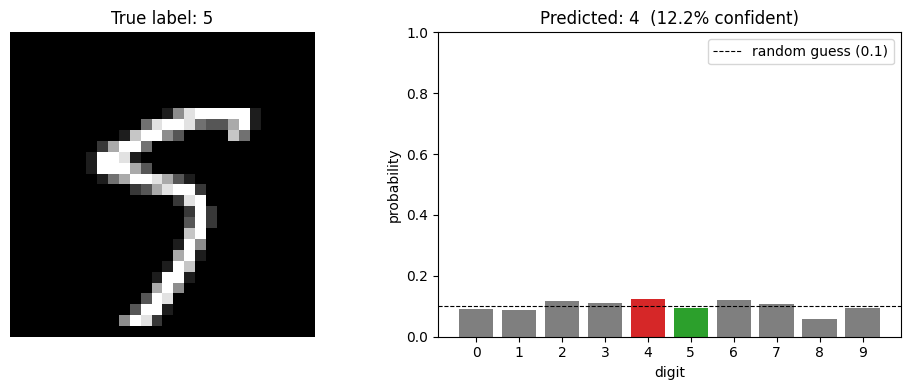

In [101]:
i = 0                                    # which validation image to look at

probs, _ = forward(x_val[i:i+1], params) # i:i+1 keeps the shape (1, 784)
probs = probs[0]                         # (1, 10) → (10,) for plotting
pred = np.argmax(probs)

fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(10, 4))

# Left: the image
ax_img.imshow(x_val[i].reshape(28, 28), cmap="gray")
ax_img.set_title(f"True label: {y_val[i]}")
ax_img.axis("off")

# Right: the predicted probabilities
colors = ["tab:gray"] * 10
colors[y_val[i]] = "tab:green"           # correct digit in green
if pred != y_val[i]:
    colors[pred] = "tab:red"             # wrong prediction in red

ax_bar.bar(range(10), probs, color=colors)
ax_bar.set_xticks(range(10))
ax_bar.set_ylim(0, 1)
ax_bar.set_xlabel("digit")
ax_bar.set_ylabel("probability")
ax_bar.set_title(f"Predicted: {pred}  ({probs[pred]:.1%} confident)")
ax_bar.axhline(0.1, color="black", linestyle="--", linewidth=0.8, label="random guess (0.1)")
ax_bar.legend()

plt.tight_layout()
plt.show()

 Visualize
- Untrained prediction: flat bars around 0.1, with no confident answer yet.
- Hidden values per activation: ReLU has a spike at 0, sigmoid sits around 0.5, tanh is centred on 0.

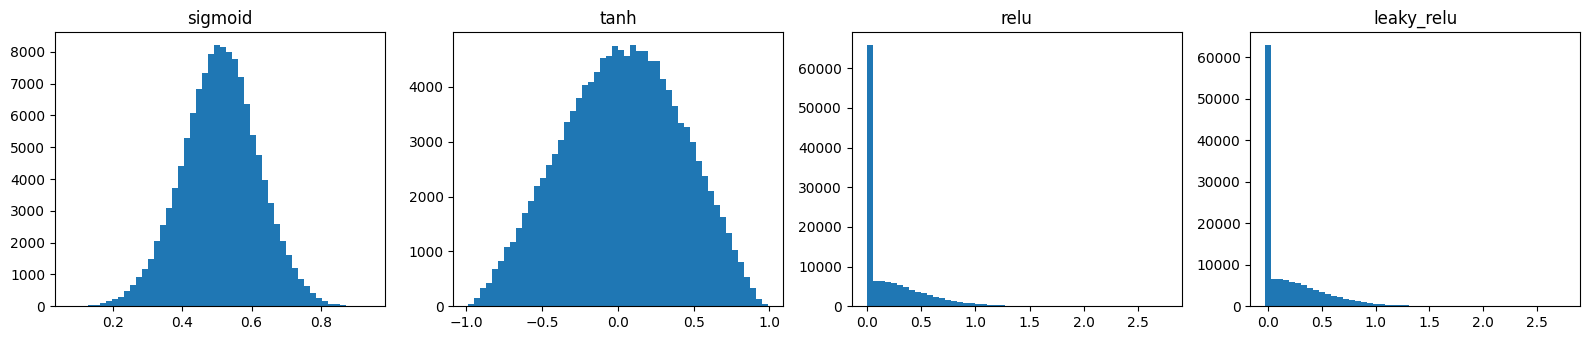

In [102]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, name in zip(axes, ACTIVATIONS):
    _, cache = forward(x_val[:1000], params, activation=name)
    ax.hist(cache["A1"].flatten(), bins=50)
    ax.set_title(name)
plt.tight_layout()
plt.show()

##Step 7: Backward Pass

Works out how to nudge every parameter to lower the loss, by running the forward pass in reverse with the chain rule.
Rule: dX always has the same shape as X.

1. dZ2 = (A2 − Y) / B: prediction minus target (softmax + cross-entropy simplify to this), averaged over the batch
2. dW2 = A1.T @ dZ2: input activity × output error
3. db2 = sum of dZ2: the same bias is used for every image, so its blame adds up
4. dA1 = dZ2 @ W2.T: send the error back to the hidden layer
5. dZ1 = dA1 * act_deriv(Z1): through the activation's slope (zero slope stops the gradient)
6. dW1 = X.T @ dZ1, db1 = sum of dZ1: same pattern, one layer back

In [103]:
def backward(cache, y_onehot, params, activation="relu"):
    _, act_deriv = ACTIVATIONS[activation]       # this time we need the derivative

    X, Z1, A1, A2 = cache["X"], cache["Z1"], cache["A1"], cache["A2"]
    B = X.shape[0]

    # Output layer
    dZ2 = (A2 - y_onehot) / B
    dW2 = A1.T @ dZ2
    db2 = dZ2.sum(axis=0, keepdims=True)

    # Hidden layer
    dA1 = dZ2 @ params["W2"].T
    dZ1 = dA1 * act_deriv(Z1)
    dW1 = X.T @ dZ1
    db1 = dZ1.sum(axis=0, keepdims=True)

    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

In [104]:
params = init_params(784, 128, 10, method="he")
Xb, yb = x_tr[:64], one_hot(y_tr[:64])

probs, cache = forward(Xb, params)
grads = backward(cache, yb, params)

for k in params:
    match = "good" if grads[k].shape == params[k].shape else "needs checking"
    print(f"{k}: param {params[k].shape}  grad {grads[k].shape}  {match}")

W1: param (784, 128)  grad (784, 128)  good
b1: param (1, 128)  grad (1, 128)  good
W2: param (128, 10)  grad (128, 10)  good
b2: param (1, 10)  grad (1, 10)  good


Gradient check

Compares backprop's gradients with numerical slopes. Nudge one weight by ±h and measure the loss change.
Relative error below 1e-5 is correct. Run in float64, because float32 can't resolve such tiny nudges.

In [105]:
def gradient_check(params, X, y_onehot, activation="relu", checks_per_param=5, h=1e-5, rng=None):
    if rng is None:
        rng = np.random.default_rng(0)

    probs, cache = forward(X, params, activation)
    grads = backward(cache, y_onehot, params, activation)

    worst = 0.0
    for name in params:
        for _ in range(checks_per_param):
            # pick one random position in this parameter
            idx = tuple(int(rng.integers(0, s)) for s in params[name].shape)
            original = params[name][idx]

            params[name][idx] = original + h
            loss_plus = cross_entropy(forward(X, params, activation)[0], y_onehot)

            params[name][idx] = original - h
            loss_minus = cross_entropy(forward(X, params, activation)[0], y_onehot)

            params[name][idx] = original               # IMPORTANT: put it back!

            numeric  = (loss_plus - loss_minus) / (2*h)
            analytic = grads[name][idx]
            rel_err  = abs(numeric - analytic) / max(1e-8, abs(numeric) + abs(analytic))
            worst = max(worst, rel_err)
            print(f"{name}{idx}: analytic={analytic: .3e}  numeric={numeric: .3e}  rel_err={rel_err:.1e}")
    return worst

In [106]:
X_small = x_tr[:20].astype(np.float64)
y_small = one_hot(y_tr[:20])
params  = init_params(784, 128, 10, method="he")

worst = gradient_check(params, X_small, y_small, activation="relu")
print("\nWorst relative error:", worst)

W1(666, 81): analytic= 3.198e-04  numeric= 3.198e-04  rel_err=7.8e-09
W1(400, 34): analytic=-1.956e-03  numeric=-1.956e-03  rel_err=6.3e-09
W1(241, 5): analytic= 3.633e-03  numeric= 3.633e-03  rel_err=5.7e-09
W1(58, 2): analytic= 0.000e+00  numeric= 0.000e+00  rel_err=0.0e+00
W1(137, 104): analytic= 0.000e+00  numeric= 0.000e+00  rel_err=0.0e+00
b1(0, 83): analytic= 0.000e+00  numeric= 0.000e+00  rel_err=0.0e+00
b1(0, 116): analytic= 0.000e+00  numeric= 0.000e+00  rel_err=0.0e+00
b1(0, 64): analytic= 3.156e-03  numeric= 3.156e-03  rel_err=3.4e-09
b1(0, 77): analytic=-5.495e-03  numeric=-5.495e-03  rel_err=6.7e-10
b1(0, 124): analytic= 8.082e-03  numeric= 8.082e-03  rel_err=2.7e-10
W2(93, 6): analytic= 5.245e-03  numeric= 5.245e-03  rel_err=1.7e-09
W2(69, 5): analytic= 1.720e-02  numeric= 1.720e-02  rel_err=3.8e-10
W2(119, 2): analytic= 1.172e-02  numeric= 1.172e-02  rel_err=2.9e-10
W2(104, 6): analytic= 6.815e-03  numeric= 6.815e-03  rel_err=8.7e-10
W2(0, 3): analytic=-2.456e-02  numer

In [107]:
for name in ACTIVATIONS:
    p = init_params(784, 128, 10, method="he")
    w = gradient_check(p, X_small, y_small, activation=name, checks_per_param=3)
    print(f"===> {name}: worst rel_err = {w:.1e}\n")

W1(666, 81): analytic= 4.739e-05  numeric= 4.739e-05  rel_err=1.4e-07
W1(400, 34): analytic=-3.802e-03  numeric=-3.802e-03  rel_err=1.1e-09
W1(241, 5): analytic= 1.898e-03  numeric= 1.898e-03  rel_err=3.7e-09
b1(0, 9): analytic=-9.958e-03  numeric=-9.958e-03  rel_err=1.5e-09
b1(0, 2): analytic= 2.224e-03  numeric= 2.224e-03  rel_err=7.7e-09
b1(0, 22): analytic= 6.731e-04  numeric= 6.731e-04  rel_err=2.1e-08
W2(104, 6): analytic= 2.802e-02  numeric= 2.802e-02  rel_err=6.8e-10
W2(116, 5): analytic= 1.122e-02  numeric= 1.122e-02  rel_err=1.3e-09
W2(77, 9): analytic=-1.579e-02  numeric=-1.579e-02  rel_err=2.6e-10
b2(0, 7): analytic= 7.832e-02  numeric= 7.832e-02  rel_err=2.7e-11
b2(0, 6): analytic= 5.891e-02  numeric= 5.891e-02  rel_err=2.0e-10
b2(0, 5): analytic= 3.404e-02  numeric= 3.404e-02  rel_err=3.8e-11
===> sigmoid: worst rel_err = 1.4e-07

W1(666, 81): analytic= 3.306e-04  numeric= 3.306e-04  rel_err=1.8e-08
W1(400, 34): analytic=-2.052e-02  numeric=-2.052e-02  rel_err=8.8e-10
W1(

Gradient strength and one test step
- The bar chart shows sigmoid has the weakest hidden-layer gradients (vanishing gradient in action).
- One step of params -= 0.1 * grads should lower the loss on the same batch.

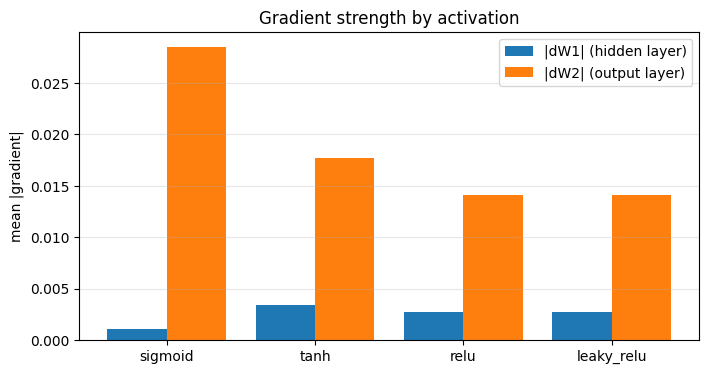

In [108]:
results = {}
for name in ACTIVATIONS:
    p = init_params(784, 128, 10, method="he")
    _, cache = forward(Xb, p, name)
    g = backward(cache, yb, p, name)
    results[name] = (np.abs(g["W1"]).mean(), np.abs(g["W2"]).mean())

names = list(results)
x = np.arange(len(names))
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, [results[n][0] for n in names], width=0.4, label="|dW1| (hidden layer)")
plt.bar(x + 0.2, [results[n][1] for n in names], width=0.4, label="|dW2| (output layer)")
plt.xticks(x, names)
plt.ylabel("mean |gradient|")
plt.title("Gradient strength by activation")
plt.legend(); plt.grid(True, axis="y", alpha=0.3)
plt.show()

In [109]:
p = init_params(784, 128, 10, method="he")
probs, cache = forward(Xb, p)
loss_before = cross_entropy(probs, yb)

g = backward(cache, yb, p)
for k in p:
    p[k] -= 0.1 * g[k]                 # step downhill

loss_after = cross_entropy(forward(Xb, p)[0], yb)
print(f"before: {loss_before:.4f}   after: {loss_after:.4f}")

before: 2.4785   after: 2.1422


In [110]:
z = np.linspace(-5, 5, 11)
h = 1e-5
numeric  = (sigmoid(z + h) - sigmoid(z - h)) / (2 * h)
analytic = sigmoid_deriv(z)
correct  = sigmoid(z) * (1 - sigmoid(z))

print("numeric :", np.round(numeric, 5))
print("analytic:", np.round(analytic, 5))
print("correct :", np.round(correct, 5))
print("sigmoid(0) =", sigmoid(0.0), "(should be 0.5)")

numeric : [0.00665 0.01766 0.04518 0.10499 0.19661 0.25    0.19661 0.10499 0.04518
 0.01766 0.00665]
analytic: [0.00665 0.01766 0.04518 0.10499 0.19661 0.25    0.19661 0.10499 0.04518
 0.01766 0.00665]
correct : [0.00665 0.01766 0.04518 0.10499 0.19661 0.25    0.19661 0.10499 0.04518
 0.01766 0.00665]
sigmoid(0) = 0.5 (should be 0.5)


##Step 8: Training Loop

For each epoch: shuffle -> for each mini-batch of 64: forward -> backward -> update -> measure train/validation metrics.

- Mini-batches: a balance between accurate gradients and many updates (~782 per epoch).
- Shuffle each epoch so the batches differ every time.
- params -= lr * grads : step against the gradient (downhill). The learning rate sets the step size.
- Every setting is an argument, and train returns a history, so experiments and plots need no code changes.

In [111]:
def evaluate(X, y, params, activation="relu"):
    probs, _ = forward(X, params, activation)
    loss = cross_entropy(probs, one_hot(y))
    acc  = np.mean(np.argmax(probs, axis=1) == y)
    return loss, acc

In [112]:
def update(params, grads, lr):
    for k in params:
        params[k] -= lr * grads[k]

In [113]:
def train(x_tr, y_tr, x_val, y_val,
          hidden_size=128, activation="relu", init="he",
          lr=0.1, epochs=10, batch_size=64, seed=42, verbose=True):

    rng = np.random.default_rng(seed)
    params = init_params(784, hidden_size, 10, method=init, rng=rng)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    n = x_tr.shape[0]

    for epoch in range(1, epochs + 1):
        # 1. Shuffle: a new random order every epoch
        idx = rng.permutation(n)
        X_shuf, y_shuf = x_tr[idx], y_tr[idx]

        # 2. Loop over mini-batches
        for start in range(0, n, batch_size):
            Xb = X_shuf[start : start + batch_size]
            yb = one_hot(y_shuf[start : start + batch_size])

            probs, cache = forward(Xb, params, activation)
            grads = backward(cache, yb, params, activation)
            update(params, grads, lr)

        # 3. Measure at the end of the epoch
        tr_loss, tr_acc   = evaluate(x_tr, y_tr, params, activation)
        val_loss, val_acc = evaluate(x_val, y_val, params, activation)

        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if verbose:
            print(f"Epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} "
                  f"| val loss {val_loss:.4f} acc {val_acc:.4f}")

    return params, history

Baseline run

ReLU, He init, 128 hidden, lr 0.1, batch 64, 10 epochs.

Result: 97.28% validation accuracy in about 16 seconds.

Validation loss was still falling at epoch 10.

In [114]:
import time
start = time.time()
params, history = train(x_tr, y_tr, x_val, y_val,
                        activation="relu", init="he", lr=0.1, epochs=10, batch_size=64)
print(f"\nTraining took {time.time() - start:.1f} seconds")

Epoch  1 | train loss 0.2642 acc 0.9207 | val loss 0.2771 acc 0.9158
Epoch  2 | train loss 0.1827 acc 0.9490 | val loss 0.2012 acc 0.9420
Epoch  3 | train loss 0.1361 acc 0.9616 | val loss 0.1592 acc 0.9542
Epoch  4 | train loss 0.1173 acc 0.9669 | val loss 0.1429 acc 0.9567
Epoch  5 | train loss 0.1007 acc 0.9715 | val loss 0.1305 acc 0.9629
Epoch  6 | train loss 0.0827 acc 0.9770 | val loss 0.1153 acc 0.9659
Epoch  7 | train loss 0.0771 acc 0.9783 | val loss 0.1111 acc 0.9677
Epoch  8 | train loss 0.0685 acc 0.9805 | val loss 0.1037 acc 0.9687
Epoch  9 | train loss 0.0622 acc 0.9838 | val loss 0.0992 acc 0.9718
Epoch 10 | train loss 0.0531 acc 0.9864 | val loss 0.0923 acc 0.9728

Training took 29.7 seconds


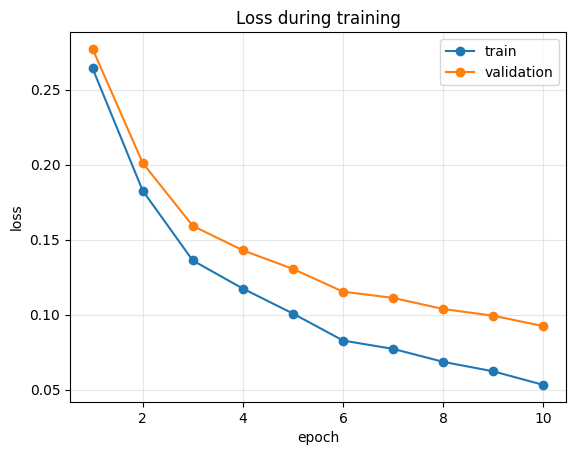

In [115]:
epochs_range = range(1, len(history["train_loss"]) + 1)
plt.plot(epochs_range, history["train_loss"], "o-", label="train")
plt.plot(epochs_range, history["val_loss"], "o-", label="validation")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Loss during training")
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

In [116]:
from google.colab import drive
drive.mount('/content/drive')

import os, json
save_dir = "/content/drive/MyDrive/mnist_project"
os.makedirs(save_dir, exist_ok=True)

np.savez(f"{save_dir}/baseline_params.npz", **params)
with open(f"{save_dir}/baseline_history.json", "w") as f:
    json.dump({k: [float(v) for v in vals] for k, vals in history.items()}, f)
print("Saved!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved!


##Step 9: Evaluate and visualize

- Learning curves: loss and accuracy per epoch. A widening train/validation gap would mean overfitting.
- Confusion matrix: cm[true, predicted]. The diagonal is correct, and off-diagonal cells show which digits get confused.
- Per-digit accuracy: the diagonal divided by the row totals.
- Mistakes: misclassified images, and the most confident mistakes.
- Learned weights: each hidden neuron's 784 weights as a 28×28 image (red = ink here excites it, blue = suppresses it).

My findings:The most confused digits were 3,5,8,9 and the best predicted digit was 0.

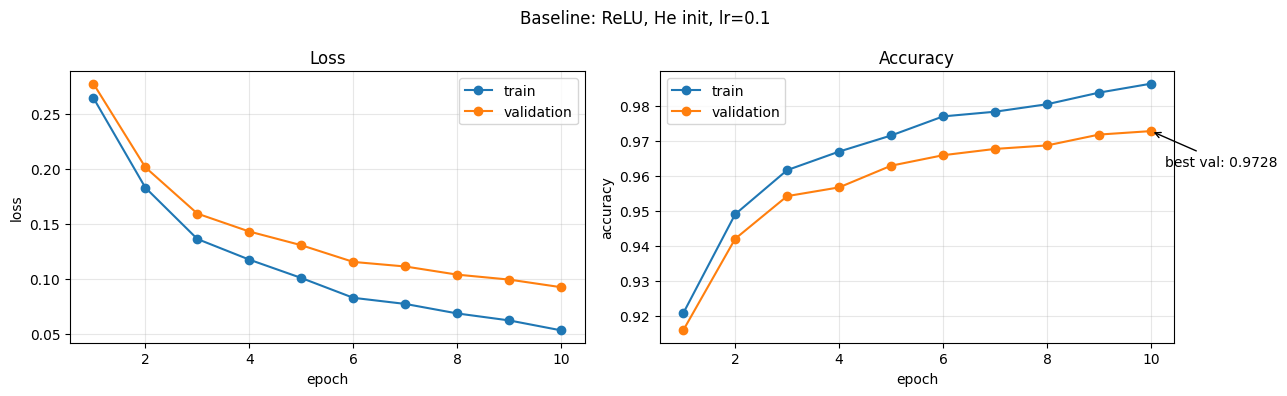

In [117]:
def plot_history(history, title="Training history"):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

    ax1.plot(epochs, history["train_loss"], "o-", label="train")
    ax1.plot(epochs, history["val_loss"], "o-", label="validation")
    ax1.set_xlabel("epoch"); ax1.set_ylabel("loss"); ax1.set_title("Loss")
    ax1.legend(); ax1.grid(True, alpha=0.3)

    ax2.plot(epochs, history["train_acc"], "o-", label="train")
    ax2.plot(epochs, history["val_acc"], "o-", label="validation")
    ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy"); ax2.set_title("Accuracy")
    ax2.legend(); ax2.grid(True, alpha=0.3)

    best = int(np.argmax(history["val_acc"]))
    ax2.annotate(f"best val: {history['val_acc'][best]:.4f}",
                 xy=(best + 1, history["val_acc"][best]),
                 xytext=(10, -25), textcoords="offset points",
                 arrowprops=dict(arrowstyle="->"))

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(history, "Baseline: ReLU, He init, lr=0.1")

In [118]:
val_preds = predict(x_val, params, "relu")

cm = np.zeros((10, 10), dtype=int)
for t, p in zip(y_val, val_preds):
    cm[t, p] += 1

print("Total counted:", cm.sum(), "| correct:", np.trace(cm))

Total counted: 10000 | correct: 9728


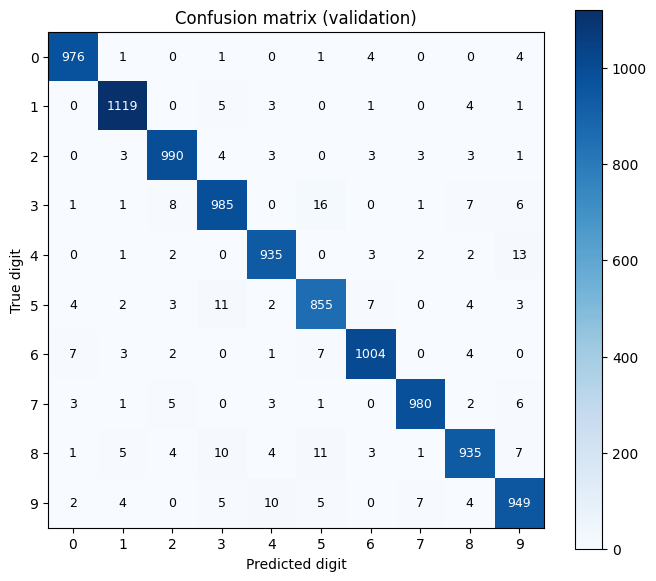

In [119]:
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues")
plt.colorbar(im)

for i in range(10):
    for j in range(10):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, cm[i, j], ha="center", va="center", color=color, fontsize=9)

ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("Predicted digit"); ax.set_ylabel("True digit")
ax.set_title("Confusion matrix (validation)")
plt.show()

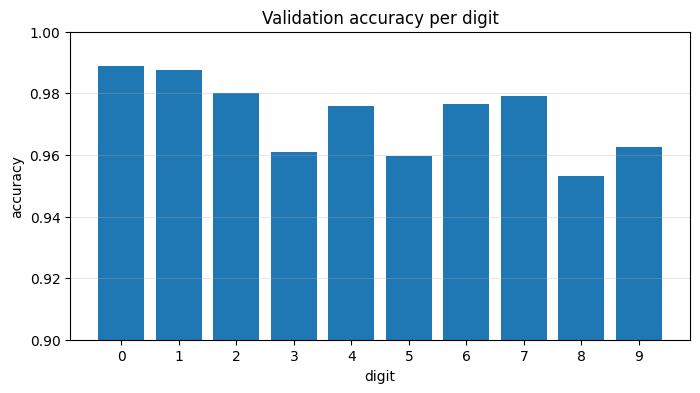

In [120]:
per_class_acc = np.diag(cm) / cm.sum(axis=1)    # correct ÷ total for each TRUE digit

plt.figure(figsize=(8, 4))
plt.bar(range(10), per_class_acc)
plt.ylim(0.9, 1.0)                               # zoom in: the differences are small
plt.xticks(range(10))
plt.xlabel("digit"); plt.ylabel("accuracy")
plt.title("Validation accuracy per digit")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

272 mistakes out of 10000


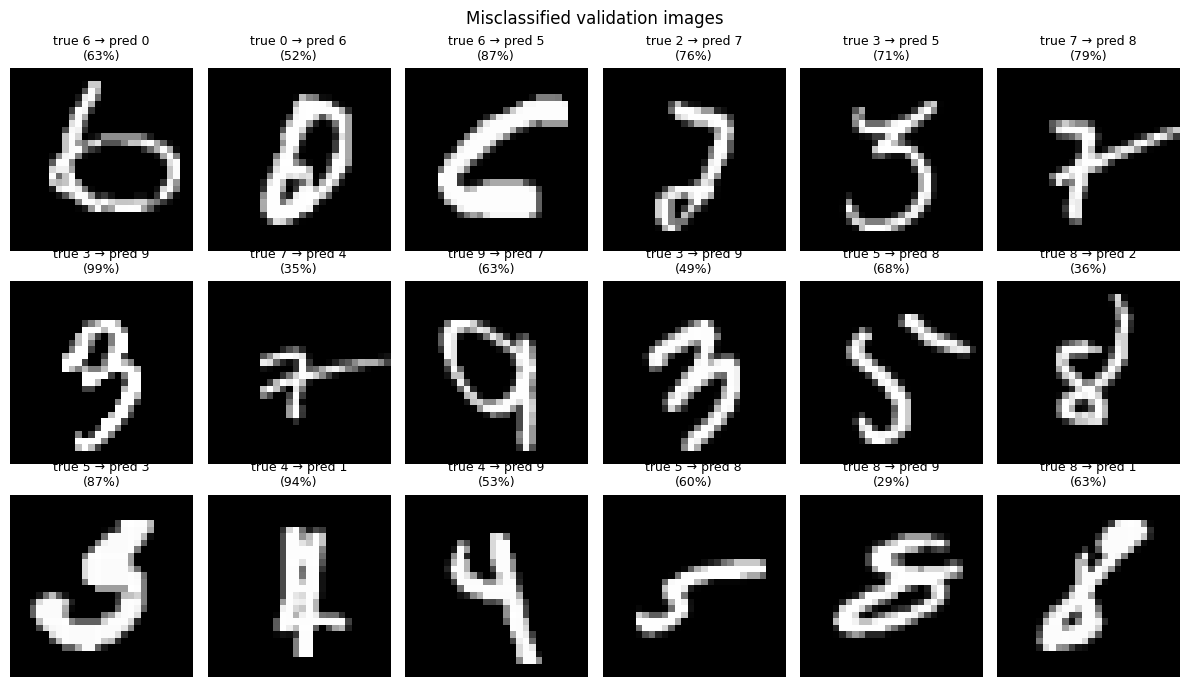

In [121]:
probs, _ = forward(x_val, params, "relu")
preds = np.argmax(probs, axis=1)
wrong = np.where(preds != y_val)[0]                 # indices of the misclassified images
print(f"{len(wrong)} mistakes out of {len(y_val)}")

fig, axes = plt.subplots(3, 6, figsize=(12, 7))
for ax, i in zip(axes.flat, wrong[:18]):
    ax.imshow(x_val[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"true {y_val[i]} → pred {preds[i]}\n({probs[i, preds[i]]:.0%})", fontsize=9)
    ax.axis("off")
plt.suptitle("Misclassified validation images")
plt.tight_layout()
plt.show()

In [122]:
confidence = probs[wrong, preds[wrong]]
most_confident_wrong = wrong[np.argsort(-confidence)]    # sorted from most to least confident

In [124]:
plt.savefig(f"{save_dir}/confusion_matrix.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

##Step 10: Experiments

Each experiment changes one setting from the baseline, with the same seed, so differences are caused by that setting.
run_experiment trains and stores results, compare overlays validation curves, and results_table summarizes everything.

In [125]:
all_results = {}     # name → {"history": ..., "config": ..., "time": ...}

def run_experiment(name, **config):
    print(f"\n=== {name} ===  {config}")
    start = time.time()
    params, history = train(x_tr, y_tr, x_val, y_val, verbose=False, **config)
    elapsed = time.time() - start
    all_results[name] = {"history": history, "config": config,
                         "time": elapsed, "params": params}
    print(f"best val acc {max(history['val_acc']):.4f} | "
          f"final val loss {history['val_loss'][-1]:.4f} | {elapsed:.1f}s")
    return params, history

In [126]:
def compare(names, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    for name in names:
        h = all_results[name]["history"]
        ep = range(1, len(h["val_loss"]) + 1)
        ax1.plot(ep, h["val_loss"], "o-", label=name, markersize=4)
        ax2.plot(ep, h["val_acc"], "o-", label=name, markersize=4)
    ax1.set_title("Validation loss"); ax1.set_xlabel("epoch"); ax1.grid(True, alpha=0.3); ax1.legend()
    ax2.set_title("Validation accuracy"); ax2.set_xlabel("epoch"); ax2.grid(True, alpha=0.3); ax2.legend()
    plt.suptitle(title); plt.tight_layout(); plt.show()

In [127]:
import pandas as pd

def results_table(names=None):
    names = names or list(all_results)
    rows = []
    for n in names:
        r = all_results[n]; h = r["history"]
        rows.append({"experiment": n,
                     "best val acc": max(h["val_acc"]),
                     "final val acc": h["val_acc"][-1],
                     "final train acc": h["train_acc"][-1],
                     "gap (train-val)": h["train_acc"][-1] - h["val_acc"][-1],
                     "time (s)": round(r["time"], 1)})
    return pd.DataFrame(rows).sort_values("best val acc", ascending=False)

##Experimenting with activations

 Activations: ReLU = Leaky ReLU (97.3%) > tanh (96.8%) > sigmoid (93.6%). Sigmoid recovers to 97.1% with lr 0.5,
because its weak gradients need bigger steps.


=== act=relu ===  {'activation': 'relu'}
best val acc 0.9728 | final val loss 0.0923 | 27.1s

=== act=leaky_relu ===  {'activation': 'leaky_relu'}
best val acc 0.9728 | final val loss 0.0928 | 30.8s

=== act=tanh ===  {'activation': 'tanh'}
best val acc 0.9675 | final val loss 0.1111 | 38.6s

=== act=sigmoid ===  {'activation': 'sigmoid'}
best val acc 0.9357 | final val loss 0.2219 | 34.8s


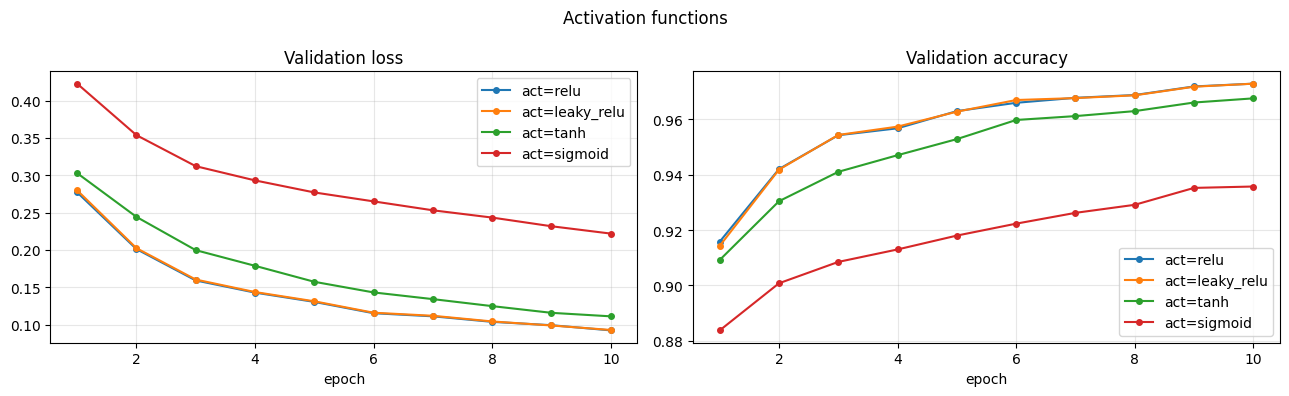

,experiment,best val acc,final val acc,final train acc,gap (train-val),time (s)
0,act=relu,0.9728,0.9728,0.98636,0.01356,27.1
1,act=leaky_relu,0.9728,0.9728,0.98618,0.01338,30.8
2,act=tanh,0.9675,0.9675,0.97942,0.01192,38.6
3,act=sigmoid,0.9357,0.9357,0.94174,0.00604,34.8


In [128]:
for act in ["relu", "leaky_relu", "tanh", "sigmoid"]:
    run_experiment(f"act={act}", activation=act)

compare(["act=relu", "act=leaky_relu", "act=tanh", "act=sigmoid"], "Activation functions")
results_table([f"act={a}" for a in ["relu", "leaky_relu", "tanh", "sigmoid"]])

In [129]:
run_experiment("act=tanh+xavier", activation="tanh", init="xavier")
run_experiment("act=sigmoid+xavier", activation="sigmoid", init="xavier")


=== act=tanh+xavier ===  {'activation': 'tanh', 'init': 'xavier'}
best val acc 0.9667 | final val loss 0.1134 | 33.5s

=== act=sigmoid+xavier ===  {'activation': 'sigmoid', 'init': 'xavier'}
best val acc 0.9341 | final val loss 0.2244 | 35.2s


({'W1': array([[ 0.01088275, -0.03714229,  0.02680183, ...,  0.01274539,
           0.05226082, -0.04245582],
         [-0.02284827, -0.033092  , -0.01392178, ..., -0.0352449 ,
          -0.00875992,  0.02776206],
         [ 0.01552736, -0.01343415, -0.00477939, ...,  0.04676967,
          -0.05722356, -0.04470169],
         ...,
         [-0.01709874, -0.03915043, -0.005696  , ...,  0.0549069 ,
           0.00618672,  0.00411947],
         [-0.05158861, -0.01340284, -0.02798535, ..., -0.04527494,
           0.02708437,  0.02378302],
         [ 0.06867016, -0.02172871,  0.01078484, ..., -0.04015694,
           0.01962557,  0.0044608 ]], shape=(784, 128)),
  'b1': array([[-0.03470107,  0.00387203,  0.0401681 , -0.0444709 ,  0.0437301 ,
          -0.03387355, -0.03455586,  0.04676816,  0.0110351 ,  0.01736099,
          -0.06456101, -0.02714845,  0.07273149, -0.04063209, -0.02183251,
          -0.0741529 ,  0.00873459,  0.02607561, -0.06032862,  0.03871914,
          -0.00258044, -0.0073

In [130]:
run_experiment("act=sigmoid lr=0.5", activation="sigmoid", lr=0.5)


=== act=sigmoid lr=0.5 ===  {'activation': 'sigmoid', 'lr': 0.5}
best val acc 0.9711 | final val loss 0.0975 | 43.6s


({'W1': array([[ 0.01539054, -0.05252713,  0.03790351, ...,  0.01802471,
           0.07390796, -0.0600416 ],
         [-0.03231233, -0.04679915, -0.01968837, ..., -0.04984381,
          -0.0123884 ,  0.03926148],
         [ 0.021959  , -0.01899875, -0.00675908, ...,  0.0661423 ,
          -0.08092633, -0.06321773],
         ...,
         [-0.02418128, -0.05536707, -0.00805535, ...,  0.07765008,
           0.00874934,  0.00582581],
         [-0.07295731, -0.01895447, -0.03957726, ..., -0.06402843,
           0.03830308,  0.03363427],
         [ 0.09711427, -0.03072904,  0.01525207, ..., -0.05679049,
           0.02775475,  0.00630853]], shape=(784, 128)),
  'b1': array([[-0.05352302, -0.06061873, -0.30962955, -0.22894001,  0.24439316,
           0.05498116, -0.02991899, -0.07486714,  0.01110898,  0.06709269,
          -0.27114352, -0.28789281, -0.04590063, -0.11800484, -0.12834194,
          -0.08581372, -0.3036203 , -0.14813501, -0.21417685, -0.20628098,
          -0.00874222, -0.0389

##Experimenting with learning rates

Learning rate: 0.01 too slow (92.7%), 0.5 best (97.8%), 1.0 unstable (best 96.9%, finished 95.4%).


=== lr=0.01 ===  {'lr': 0.01}
best val acc 0.9273 | final val loss 0.2495 | 36.2s

=== lr=0.05 ===  {'lr': 0.05}
best val acc 0.9642 | final val loss 0.1231 | 36.0s

=== lr=0.1 ===  {'lr': 0.1}
best val acc 0.9728 | final val loss 0.0923 | 40.1s

=== lr=0.5 ===  {'lr': 0.5}
best val acc 0.9776 | final val loss 0.0900 | 34.5s

=== lr=1.0 ===  {'lr': 1.0}
best val acc 0.9685 | final val loss 0.1968 | 31.0s


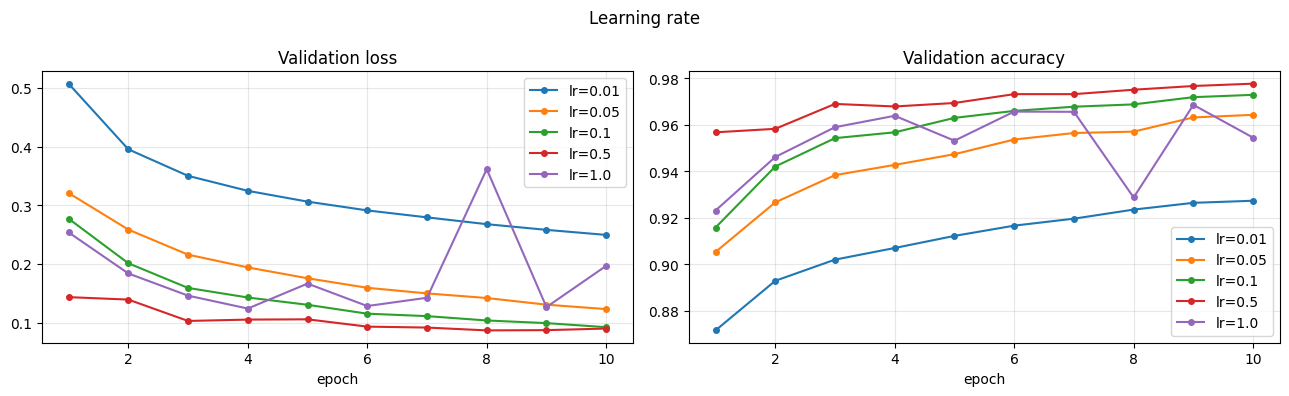

In [131]:
for lr in [0.01, 0.05, 0.1, 0.5, 1.0]:
    run_experiment(f"lr={lr}", lr=lr)

compare([f"lr={lr}" for lr in [0.01, 0.05, 0.1, 0.5, 1.0]], "Learning rate")

##Experimenting with hidden layer size

Hidden size: big gains up to 128, then flat, while training time keeps rising. Diminishing returns.

In [132]:
sizes = [16, 32, 64, 128, 256, 512]
for h in sizes:
    run_experiment(f"hidden={h}", hidden_size=h)


=== hidden=16 ===  {'hidden_size': 16}
best val acc 0.9454 | final val loss 0.1909 | 12.2s

=== hidden=32 ===  {'hidden_size': 32}
best val acc 0.9600 | final val loss 0.1611 | 10.2s

=== hidden=64 ===  {'hidden_size': 64}
best val acc 0.9666 | final val loss 0.1149 | 22.5s

=== hidden=128 ===  {'hidden_size': 128}
best val acc 0.9728 | final val loss 0.0923 | 25.6s

=== hidden=256 ===  {'hidden_size': 256}
best val acc 0.9738 | final val loss 0.0900 | 58.1s

=== hidden=512 ===  {'hidden_size': 512}
best val acc 0.9734 | final val loss 0.0840 | 98.6s


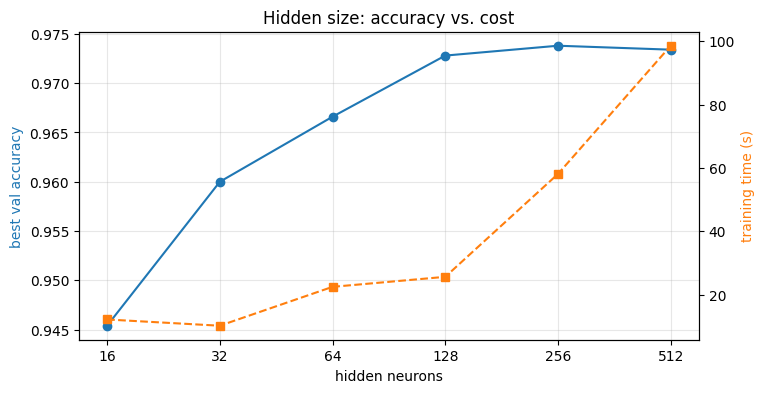

In [133]:
accs  = [max(all_results[f"hidden={h}"]["history"]["val_acc"]) for h in sizes]
times = [all_results[f"hidden={h}"]["time"] for h in sizes]

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(sizes, accs, "o-", color="tab:blue", label="best val acc")
ax1.set_xscale("log", base=2); ax1.set_xticks(sizes); ax1.set_xticklabels(sizes)
ax1.set_xlabel("hidden neurons"); ax1.set_ylabel("best val accuracy", color="tab:blue")
ax2 = ax1.twinx()                                    # a second y-axis on the right
ax2.plot(sizes, times, "s--", color="tab:orange", label="time")
ax2.set_ylabel("training time (s)", color="tab:orange")
plt.title("Hidden size: accuracy vs. cost"); ax1.grid(True, alpha=0.3)
plt.show()

##Experimenting with Initialization

Initialization: zeros stays stuck at 11.3% (it always predicts "1", the most common digit). The others are within 0.2% of each other.


=== init=zeros ===  {'init': 'zeros'}
best val acc 0.1133 | final val loss 2.3015 | 30.1s

=== init=small ===  {'init': 'small'}
best val acc 0.9707 | final val loss 0.1014 | 27.8s

=== init=xavier ===  {'init': 'xavier'}
best val acc 0.9723 | final val loss 0.0929 | 27.4s

=== init=he ===  {'init': 'he'}
best val acc 0.9728 | final val loss 0.0923 | 30.0s


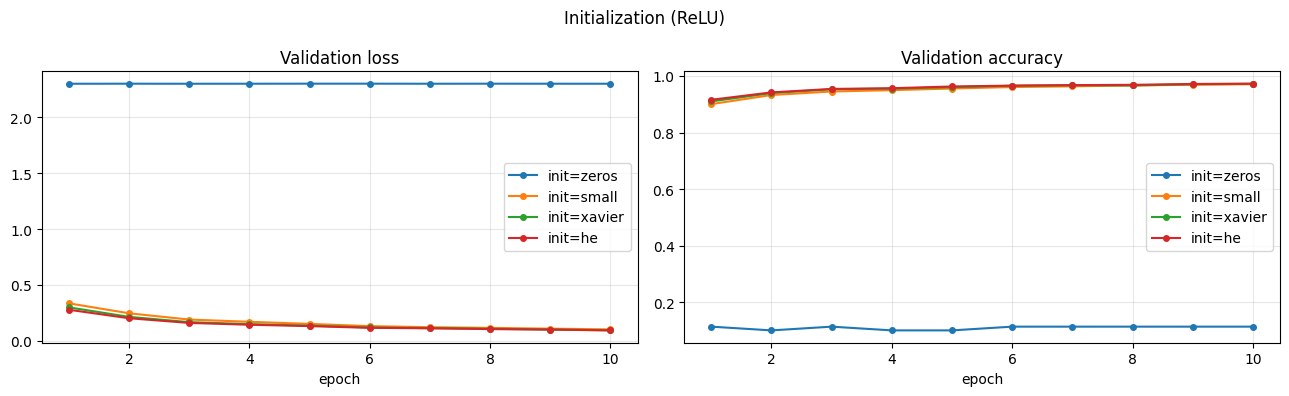

In [134]:
for init in ["zeros", "small", "xavier", "he"]:
    run_experiment(f"init={init}", init=init)

compare([f"init={i}" for i in ["zeros", "small", "xavier", "he"]], "Initialization (ReLU)")

##Experimenting with Batch Size

Batch size: 16 -> 97.8%, 1024 -> 91.7%, mostly because big batches take far fewer steps per epoch.


=== batch=16 ===  {'batch_size': 16}
best val acc 0.9779 | final val loss 0.0849 | 47.6s

=== batch=64 ===  {'batch_size': 64}
best val acc 0.9728 | final val loss 0.0923 | 30.2s

=== batch=256 ===  {'batch_size': 256}
best val acc 0.9496 | final val loss 0.1720 | 21.4s

=== batch=1024 ===  {'batch_size': 1024}
best val acc 0.9168 | final val loss 0.2878 | 24.1s


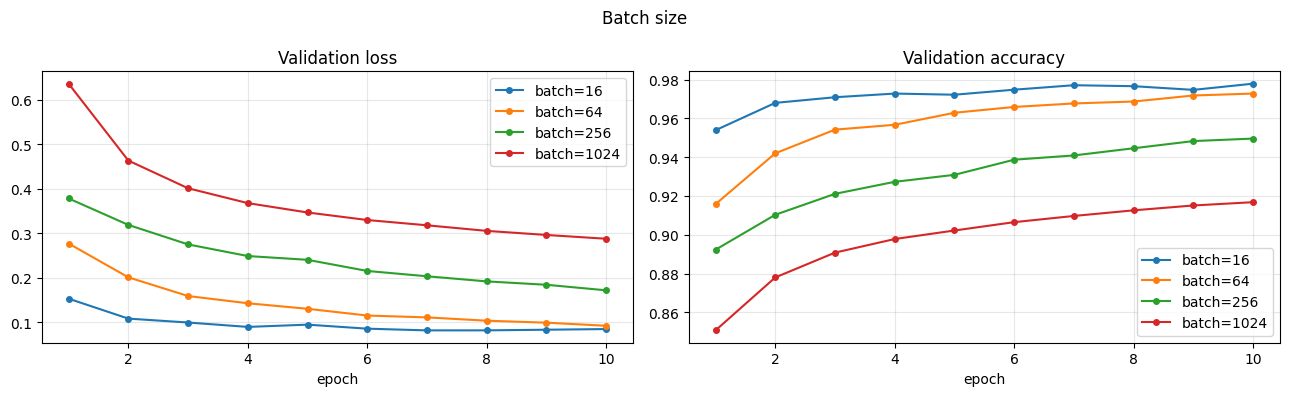

,experiment,best val acc,final val acc,final train acc,gap (train-val),time (s)
0,batch=16,0.9779,0.9779,0.99734,0.01944,47.6
1,batch=64,0.9728,0.9728,0.98636,0.01356,30.2
2,batch=256,0.9496,0.9496,0.95788,0.00828,21.4
3,batch=1024,0.9168,0.9168,0.92188,0.00508,24.1


In [135]:
for bs in [16, 64, 256, 1024]:
    run_experiment(f"batch={bs}", batch_size=bs)

compare([f"batch={bs}" for bs in [16, 64, 256, 1024]], "Batch size")
results_table([f"batch={bs}" for bs in [16, 64, 256, 1024]])

##Experimenting with longer training

40 epochs: validation peaks around 97.7% then slips while train accuracy approaches 100%. That's overfitting.


=== baseline 40 epochs ===  {'epochs': 40}
best val acc 0.9770 | final val loss 0.0855 | 115.4s


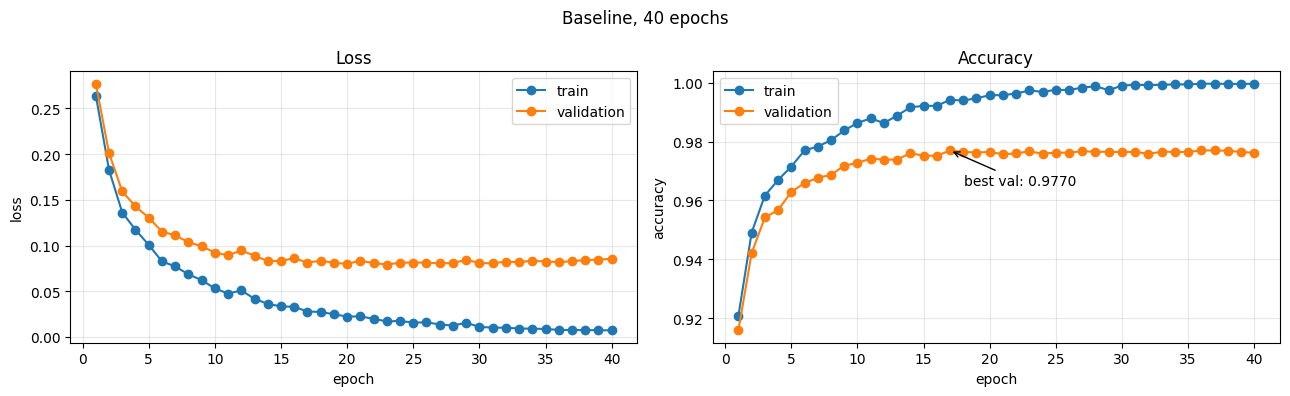

In [136]:
run_experiment("baseline 40 epochs", epochs=40)
plot_history(all_results["baseline 40 epochs"]["history"], "Baseline, 40 epochs")

Best combination: 98.18% validation.

The differences under about 0.2% are within noise for 10,000 validation images.

In [137]:
run_experiment("best combo", activation="relu", lr=0.5, hidden_size=256, epochs=16)
results_table()


=== best combo ===  {'activation': 'relu', 'lr': 0.5, 'hidden_size': 256, 'epochs': 16}
best val acc 0.9818 | final val loss 0.0716 | 82.8s


,experiment,best val acc,final val acc,final train acc,gap (train-val),time (s)
27,best combo,0.9818,0.9816,1.00000,0.01840,82.8
22,batch=16,0.9779,0.9779,0.99734,0.01944,47.6
10,lr=0.5,0.9776,0.9776,0.99688,0.01928,34.5
26,baseline 40 epochs,0.9770,0.9762,0.99968,0.02348,115.4
16,hidden=256,0.9738,0.9728,0.98754,0.01474,58.1
17,hidden=512,0.9734,0.9731,0.99032,0.01722,98.6
21,init=he,0.9728,0.9728,0.98636,0.01356,30.0
15,hidden=128,0.9728,0.9728,0.98636,0.01356,25.6
23,batch=64,0.9728,0.9728,0.98636,0.01356,30.2
0,act=relu,0.9728,0.9728,0.98636,0.01356,27.1


In [138]:
to_save = {n: {"history": {k: [float(v) for v in vals] for k, vals in r["history"].items()},
               "config": r["config"], "time": r["time"]}
           for n, r in all_results.items()}
with open(f"{save_dir}/experiments.json", "w") as f:
    json.dump(to_save, f, indent=2)

np.savez(f"{save_dir}/best_params.npz", **all_results["best combo"]["params"])

##Step 11:Test and evaluations

The test set has never been used for any decision. It's evaluated once, with no changes afterwards.

Result: 98.24% test accuracy (176 mistakes out of 10,000), within noise of validation (98.16%),
so the model generalizes well.

In [140]:
best = all_results["best combo"]
best_params = best["params"]
best_act = best["config"].get("activation", "relu")

test_loss, test_acc = evaluate(x_test, y_test, best_params, best_act)
val_loss, val_acc = evaluate(x_val, y_val, best_params, best_act)

print(f"Validation accuracy: {val_acc:.4f}")
print(f"TEST accuracy:       {test_acc:.4f}  ")
print(f"Test errors: {int(round((1 - test_acc) * len(y_test)))} out of {len(y_test)}")

Validation accuracy: 0.9816
TEST accuracy:       0.9824  
Test errors: 176 out of 10000


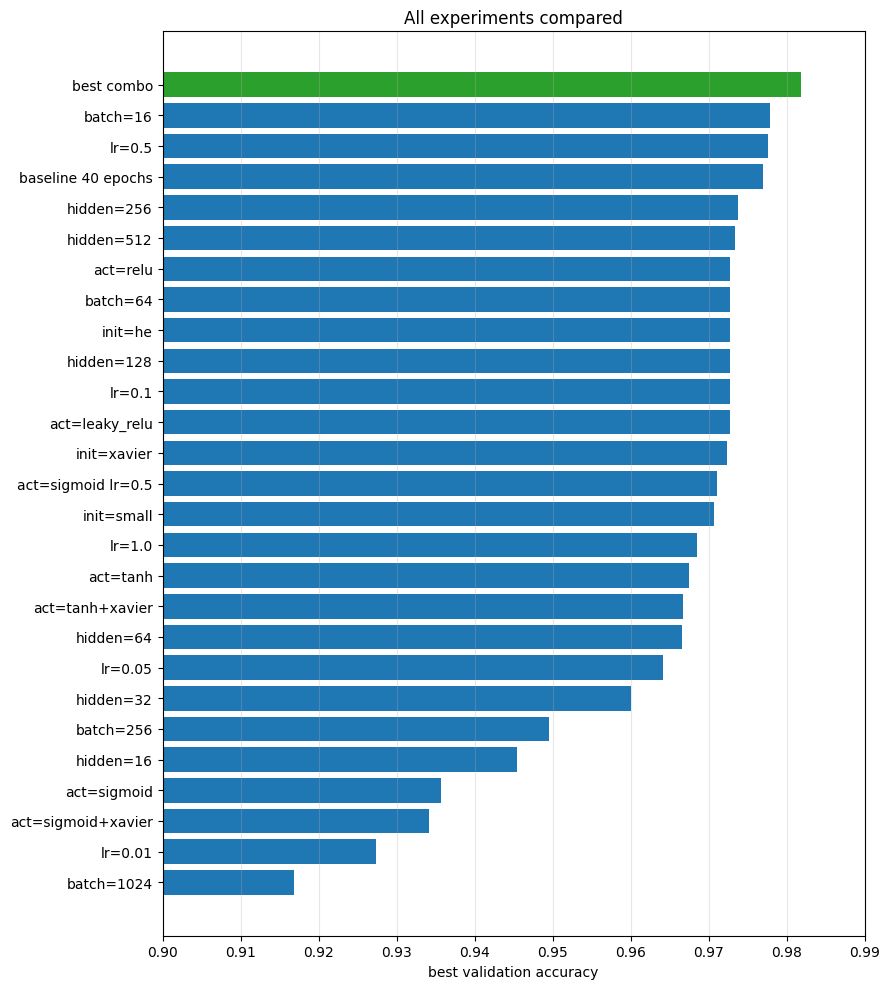

In [141]:
df = results_table().sort_values("best val acc")
df = df[df["experiment"] != "init=zeros"]         # leave out the 11% run so the scale stays readable

plt.figure(figsize=(9, 10))
colors = ["tab:green" if e == "best combo" else "tab:blue" for e in df["experiment"]]
plt.barh(df["experiment"], df["best val acc"], color=colors)
plt.xlim(0.90, 0.99)
plt.xlabel("best validation accuracy")
plt.title("All experiments compared")
plt.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{save_dir}/all_experiments.png", dpi=150, bbox_inches="tight")
plt.show()